# DSCI 552 Homework 3
**Name:** Yang Zhao  
**USC NetID:** yzhao528

## 1. Time Series Classification Part 1: Feature Creation/Extraction
### 1(a) AReM dataset
The supplied AReM archive is used without downloading another copy. Each CSV is one activity instance with six channels. The original CSV bytes are preserved in `data/AReM/`. All 88 files are checked below.

**Reasoning:** a recording is the classification unit because it corresponds to one performed activity. Treating its 480 timestamps as separate instances would change the task and inflate the sample count. Using the supplied archive also keeps the analysis tied to the assigned data.

In [1]:
from pathlib import Path
import re
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 552
B = 10_000
DATA = Path("data/AReM")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
CHANNELS = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
TYPES = ["min", "max", "mean", "median", "std", "q1", "q3"]
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [2]:
def read_instance(path):
    rows = []
    whitespace_rows = trailing_rows = 0
    for line_no, line in enumerate(path.read_text().splitlines(), start=1):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        whitespace_rows += int("," not in line)
        if line.endswith(","):
            trailing_rows += 1
            line = line[:-1].rstrip()  # remove one empty trailing field only
        fields = re.split(r"[,\s]+", line)
        if len(fields) != 7:
            raise ValueError(f"{path}, line {line_no}: expected 7 numeric fields")
        try:
            rows.append([float(v) for v in fields])
        except ValueError as exc:
            raise ValueError(f"{path}, line {line_no}: nonnumeric data") from exc
    array = np.asarray(rows, dtype=float)
    assert array.ndim == 2 and array.shape[1] == 7
    assert np.isfinite(array).all(), f"Nonfinite value in {path}"
    times = array[:, 0]
    expected_times = np.arange(0, 120000, 250)
    assert len(np.unique(times)) == len(times), f"Duplicate timestamp: {path}"
    assert (np.diff(times) > 0).all(), f"Unordered timestamps: {path}"
    assert np.isin(times, expected_times).all(), f"Unexpected timestamp: {path}"
    missing = np.setdiff1d(expected_times, times).astype(int).tolist()
    info = dict(activity=path.parent.name, file=path.name,
                n_observations=len(rows), whitespace_rows=whitespace_rows,
                trailing_delimiter_rows=trailing_rows,
                missing_timestamps_ms=",".join(map(str, missing)) or "none")
    return array[:, 1:], info

files = sorted(DATA.glob("*/*.csv"), key=lambda p: (p.parent.name, int(p.stem[7:])))
assert len(files) == 88
assert {p.parent.name for p in files} == {"bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"}
instances, audit_rows = [], []
for path in files:
    values, info = read_instance(path)
    instances.append(values)
    audit_rows.append(info)
audit = pd.DataFrame(audit_rows)
assert audit.n_observations.value_counts().to_dict() == {480: 87, 479: 1}
assert audit.loc[audit.n_observations.eq(479), ["activity", "file", "missing_timestamps_ms"]].values.tolist() == [["sitting", "dataset8.csv", "13500"]]
audit.to_csv(RESULTS / "data_audit.csv", index=False)
exceptions = audit[(audit.n_observations != 480) | (audit.whitespace_rows > 0) | (audit.trailing_delimiter_rows > 0)]
display(exceptions)
print(f"Verified {len(files)} instances; {sum(map(len, instances)):,} observed rows; no observed rows discarded.")

,activity,file,n_observations,whitespace_rows,trailing_delimiter_rows,missing_timestamps_ms
10,bending2,dataset4.csv,480,480,0,none
21,cycling,dataset9.csv,480,0,1,none
26,cycling,dataset14.csv,480,0,1,none
50,sitting,dataset8.csv,479,0,0,13500


Verified 88 instances; 42,239 observed rows; no observed rows discarded.


**Cleaning and completeness.** `bending2/dataset4.csv` has 480 whitespace-delimited rows; `cycling/dataset9.csv` and `cycling/dataset14.csv` each have one extra trailing comma. The parser accepts those delimiters, checks every numeric row, and raises an error on unexpected content. `sitting/dataset8.csv` has 479 rows, with timestamp 13,500 ms missing in the original archive. Its statistics use all 479 observed values without imputation. The remaining 87 instances each have 480 rows: 42,239 observed rows in total. No valid data are discarded. The comment header identifies channel 5 and 6 as `avg_rss23` and `var_rss23` (correcting typographical omissions in the assignment).

**Reasoning for cleaning:** changing separators restores the intended seven numeric fields without changing measurements. Interpolating the absent row would add an unobserved value and could alter extrema, quartiles, and standard deviations, so the reported statistics describe the available observations. This avoids fabrication, although the missing point may cause an unknown small difference from a complete-recording summary.

### 1(b) Required train/test split

In [3]:
metadata = audit[["activity", "file", "n_observations"]].copy()
metadata.insert(0, "instance", np.arange(1, 89))
metadata["dataset_number"] = metadata.file.str.extract(r"dataset(\d+)").astype(int)
cutoff = np.where(metadata.activity.isin(["bending1", "bending2"]), 2, 3)
metadata["split"] = np.where(metadata.dataset_number <= cutoff, "test", "train")
split_counts = pd.crosstab(metadata.activity, metadata.split).reindex(columns=["train", "test"])
split_counts["total"] = split_counts.sum(axis=1)
assert metadata.split.value_counts().to_dict() == {"train": 69, "test": 19}
for activity, group in metadata.groupby("activity"):
    required = {1, 2} if activity in {"bending1", "bending2"} else {1, 2, 3}
    assert set(group.loc[group.split.eq("test"), "dataset_number"]) == required
assert not set(metadata.index[metadata.split.eq("train")]) & set(metadata.index[metadata.split.eq("test")])
metadata.to_csv(RESULTS / "split_manifest.csv", index=False)
display(split_counts.assign(total=split_counts.total).rename_axis("activity"))
print("Training: 69; test: 19; total: 88.")

split,train,test,total
activity,,,
bending1,5,2,7
bending2,4,2,6
cycling,12,3,15
lying,12,3,15
sitting,12,3,15
standing,12,3,15
walking,12,3,15


Training: 69; test: 19; total: 88.


**Result:** bending1 contributes 5 training / 2 test instances; bending2 contributes 4 / 2; each of cycling, lying, sitting, standing, and walking contributes 12 / 3. No random splitting is used.

**Reasoning:** the activity totals are 7, 6, and five groups of 15. Thus total instances = 7 + 6 + 5(15) = 88; test instances = 2 + 2 + 5(3) = 19; training instances = (7 - 2) + (6 - 2) + 5(15 - 3) = 69. The split uses file membership, rather than timestamps, to keep all measurements from a recording together and to match the assignment exactly.

### 1(c)(i) Common time-domain features
Common choices include minimum, maximum, range; mean, median and quantiles; variance, standard deviation and interquartile range; skewness and kurtosis; energy and root mean square; average absolute successive change, slope, zero/level crossings, peaks, and lag autocorrelation. Distribution summaries describe level and spread; change and correlation features also retain information about temporal order.

Sources: [tsfresh's feature overview](https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html) documents these types. The [catch22 authors' repository](https://github.com/DynamicsAndNeuralSystems/catch22) explains that raw mean and standard deviation can supplement dynamical descriptors when location and spread matter. Only the seven requested types are extracted here.

**Reasoning:** activity can affect both signal level and movement variability, so level, spread, and extremes provide complementary summaries. Autocorrelation and successive changes can distinguish temporal dynamics even when two recordings have similar distributions. The requested seven summaries intentionally capture distribution information, not the complete sequence order.

### 1(c)(ii) Extract 42 features per instance
Use raw channel values. Within each instance, `std` is the **sample** standard deviation (`ddof=1`); quartiles use NumPy's linear interpolation. The feature frame has exactly 88 rows and 42 numeric columns; identifiers and split labels are stored separately and included in the exported CSV for traceability. Channel order is: 1 avg_rss12, 2 var_rss12, 3 avg_rss13, 4 var_rss13, 5 avg_rss23, 6 var_rss23.

In [4]:
def feature_name(kind, channel):
    return f"{kind}_{channel}" if kind in ["q1", "q3"] else f"{kind}{channel}"

feature_rows = []
for values in instances:
    row = {}
    for j in range(6):
        x = values[:, j]
        stats = [x.min(), x.max(), x.mean(), np.median(x), x.std(ddof=1),
                 np.quantile(x, 0.25, method="linear"), np.quantile(x, 0.75, method="linear")]
        row.update({feature_name(kind, j+1): value for kind, value in zip(TYPES, stats)})
    feature_rows.append(row)
features = pd.DataFrame(feature_rows, index=pd.Index(metadata.instance, name="instance"))
assert features.shape == (88, 42)
assert features.columns.is_unique and np.isfinite(features.to_numpy()).all()
export = pd.concat([metadata.set_index("instance"), features], axis=1)
export.to_csv(RESULTS / "extracted_features.csv")
print(f"Feature dataframe: {features.shape[0]} rows × {features.shape[1]} numeric feature columns.")
# Render all 88 × 42 values as six readable tables instead of one very wide table.
for channel in range(1, 7):
    display(Markdown(f"**Time series {channel}: {CHANNELS[channel-1]}**"))
    cols = [feature_name(kind, channel) for kind in TYPES]
    display(export[["activity", "file", "split"] + cols])

Feature dataframe: 88 rows × 42 numeric feature columns.


**Time series 1: avg_rss12**

,activity,file,split,min1,max1,mean1,median1,std1,q1_1,q3_1
instance,,,,,,,,,,
1,bending1,dataset1.csv,test,37.2500,45.0000,40.6248,40.5000,1.4770,39.2500,42.0000
2,bending1,dataset2.csv,test,38.0000,45.6700,42.8128,42.5000,1.4355,42.0000,43.6700
3,bending1,dataset3.csv,train,35.0000,47.4000,43.9545,44.3300,1.5588,43.0000,45.0000
4,bending1,dataset4.csv,train,33.0000,47.7500,42.1798,43.5000,3.6707,39.1500,45.0000
5,bending1,dataset5.csv,train,33.0000,45.7500,41.6781,41.7500,2.2435,41.3300,42.7500
6,bending1,dataset6.csv,train,37.0000,48.0000,43.4550,43.2500,1.3861,42.5000,45.0000
7,bending1,dataset7.csv,train,36.2500,48.0000,43.9691,44.5000,1.6184,43.3100,44.6700
8,bending2,dataset1.csv,test,12.7500,51.0000,24.5630,24.2500,3.7375,23.1875,26.5000
9,bending2,dataset2.csv,test,0.0000,42.7500,27.4646,28.0000,3.5836,25.5000,30.0000


**Time series 2: var_rss12**

,activity,file,split,min2,max2,mean2,median2,std2,q1_2,q3_2
instance,,,,,,,,,,
1,bending1,dataset1.csv,test,0.0000,1.3000,0.3586,0.4300,0.3226,0.0000,0.5000
2,bending1,dataset2.csv,test,0.0000,1.2200,0.3724,0.4700,0.2892,0.0000,0.5000
3,bending1,dataset3.csv,train,0.0000,1.7000,0.4263,0.4700,0.3387,0.0000,0.5000
4,bending1,dataset4.csv,train,0.0000,3.0000,0.6960,0.5000,0.6309,0.0000,1.1200
5,bending1,dataset5.csv,train,0.0000,2.8300,0.5360,0.5000,0.4055,0.4300,0.7100
6,bending1,dataset6.csv,train,0.0000,1.5800,0.3781,0.4700,0.3156,0.0000,0.5000
7,bending1,dataset7.csv,train,0.0000,1.5000,0.4131,0.4700,0.2631,0.4300,0.5000
8,bending2,dataset1.csv,test,0.0000,6.8700,0.5908,0.4300,0.8374,0.0000,0.7100
9,bending2,dataset2.csv,test,0.0000,7.7600,0.4497,0.4300,0.7672,0.0000,0.5000


...

,activity,file,split,min4,max4,mean4,median4,std4,q1_4,q3_4
instance,,,,,,,,,,
1,bending1,dataset1.csv,test,0.0000,7.2300,0.8325,0.5000,0.9657,0.0000,1.1200
2,bending1,dataset2.csv,test,0.0000,5.7600,0.8764,0.5000,1.0473,0.0000,1.1450
3,bending1,dataset3.csv,train,0.0000,4.4400,0.4973,0.4300,0.5507,0.0000,0.8300
4,bending1,dataset4.csv,train,0.0000,5.1500,0.9899,0.8300,0.9537,0.4300,1.3000
5,bending1,dataset5.csv,train,0.0000,6.4200,0.8419,0.5000,0.9288,0.4300,1.1200
6,bending1,dataset6.csv,train,0.0000,10.0300,0.8494,0.5000,0.9958,0.4300,1.1200
7,bending1,dataset7.csv,train,0.0000,5.1700,0.6664,0.4700,0.7890,0.0000,0.9400
8,bending2,dataset1.csv,test,0.0000,6.7600,0.7368,0.4700,0.9270,0.0000,0.8700
9,bending2,dataset2.csv,test,0.0000,5.7600,0.7799,0.5000,0.9044,0.0000,0.9400


**Time series 5: avg_rss23**

,activity,file,split,min5,max5,mean5,median5,std5,q1_5,q3_5
instance,,,,,,,,,,
1,bending1,dataset1.csv,test,27.2500,38.2500,34.3113,35.0000,2.1884,33.0000,36.0000
2,bending1,dataset2.csv,test,27.6700,38.5000,33.0246,33.0000,1.9953,32.0000,34.5000
3,bending1,dataset3.csv,train,29.0000,38.5000,35.5885,36.0000,1.9996,35.3625,36.5000
4,bending1,dataset4.csv,train,20.0000,38.6700,33.4939,35.0000,3.8494,30.4575,36.3300
5,bending1,dataset5.csv,train,23.6700,37.5000,29.8571,30.0000,2.4110,28.4575,31.2500
6,bending1,dataset6.csv,train,8.0000,33.5000,23.0348,23.5000,2.4889,22.2500,24.0000
7,bending1,dataset7.csv,train,11.3300,30.7500,22.1038,21.6700,3.3183,20.5000,23.7500
8,bending2,dataset1.csv,test,10.6700,30.0000,23.4930,23.7500,3.6938,20.5000,27.0000
9,bending2,dataset2.csv,test,0.0000,33.0000,17.6179,18.0000,5.0536,15.0000,20.7500


**Time series 6: var_rss23**

,activity,file,split,min6,max6,mean6,median6,std6,q1_6,q3_6
instance,,,,,,,,,,
1,bending1,dataset1.csv,test,0.0000,1.9200,0.5706,0.4300,0.5829,0.0000,1.3000
2,bending1,dataset2.csv,test,0.0000,3.1100,0.5711,0.4300,0.6010,0.0000,1.3000
3,bending1,dataset3.csv,train,0.0000,1.7900,0.4933,0.4300,0.5135,0.0000,0.9400
4,bending1,dataset4.csv,train,0.0000,2.1800,0.6135,0.5000,0.5243,0.0000,1.0000
5,bending1,dataset5.csv,train,0.0000,1.7900,0.3833,0.4300,0.3892,0.0000,0.5000
6,bending1,dataset6.csv,train,0.0000,5.2600,0.6796,0.5000,0.6225,0.4300,0.8700
7,bending1,dataset7.csv,train,0.0000,2.9600,0.5553,0.4900,0.4878,0.0000,0.8300
8,bending2,dataset1.csv,test,0.0000,4.9700,0.7002,0.5000,0.6937,0.4300,0.8700
9,bending2,dataset2.csv,test,0.0000,6.7600,1.1221,0.8300,1.0123,0.4700,1.3000


**Interpretation:** one row represents an entire recording, rather than an individual timestamp. All seven summaries are retained for all six channels. Displayed values are rounded to four decimals; the CSV preserves numeric precision. The one shorter recording uses the same definitions with n = 479.

**Definitions and reasoning:** for one channel with observed values $x_1,\ldots,x_n$, the mean is $\bar x=n^{-1}\sum_t x_t$ and the sample standard deviation is $s=\sqrt{\sum_t(x_t-\bar x)^2/(n-1)}$. Minimum and maximum record the observed bounds; mean measures typical level, median gives a location summary less sensitive to extreme values, standard deviation measures spread, and q1/q3 describe the central distribution. For a quantile at probability $p$, set $h=(n-1)p$, $k=\lfloor h\rfloor$, and $a=h-k$. With sorted values indexed from zero, use $(1-a)x_{(k)}+ax_{(k+1)}$; this also defines the median at $p=0.5$.

There are six independent sets of seven summary columns, so each recording yields $6\times7=42$ numeric features. The denominator $n-1$ defines the conventional sample statistic; temporal dependence means it should not be interpreted as a guarantee of unbiased variance estimation here. Raw values retain physical level and spread; per-recording z-scoring would make every channel mean zero and standard deviation one, removing these potentially useful differences. Column standardization is unnecessary for the descriptive summaries and scale-independent eta-squared comparison used here. These summaries discard ordering, so recordings with permuted timestamps have identical extracted features.


### 1(c)(iii) Standard deviations and 90% bootstrap confidence intervals
For each feature column $f$, estimate its across-instance sample standard deviation:
$$s_f=\sqrt{\frac{1}{87}\sum_{i=1}^{88}(z_{if}-\bar z_f)^2}.$$
Use the **nonparametric percentile bootstrap**, B = 10,000 and seed = 552. Each resample draws 88 instance rows with replacement from the full 88 × 42 frame and computes the 42 sample standard deviations (`ddof=1`). The interval endpoints are the 5th and 95th percentiles of the bootstrap estimates, with linear quantile interpolation. Resampling whole rows preserves dependence between features; time points within a recording are not resampled.

These are marginal, pointwise 90% intervals, not simultaneous intervals. They describe between-recording variation under an independent-recording sampling approximation, conditional on the observed activity mixture; they do not establish generalization to new subjects. Using all 88 recordings here is explicitly required; feature selection below uses training data only.

In [5]:
rng = np.random.default_rng(SEED)
X = features.to_numpy()
bootstrap_std = np.empty((B, X.shape[1]))
# Batches limit memory; the random row draws are reproducible.
for start in range(0, B, 250):
    stop = min(start + 250, B)
    indices = rng.integers(0, len(X), size=(stop-start, len(X)))
    bootstrap_std[start:stop] = X[indices].std(axis=1, ddof=1)
lo, hi = np.quantile(bootstrap_std, [0.05, 0.95], axis=0, method="linear")
bootstrap_table = pd.DataFrame({"feature": features.columns,
    "estimated_std": X.std(axis=0, ddof=1), "ci_lower_90": lo, "ci_upper_90": hi})
assert len(bootstrap_table) == 42
assert np.isfinite(bootstrap_table.iloc[:, 1:].to_numpy()).all()
assert (bootstrap_table.ci_lower_90 <= bootstrap_table.ci_upper_90).all()
bootstrap_table.to_csv(RESULTS / "bootstrap_std_90.csv", index=False)
display(bootstrap_table)

,feature,estimated_std,ci_lower_90,ci_upper_90
0,min1,9.5700,8.2622,10.7614
1,max1,4.3944,3.3280,5.2849
2,mean1,5.3357,4.7040,5.8864
3,median1,5.4401,4.7903,6.0043
4,std1,1.7722,1.5722,1.9500
5,q1_1,6.1536,5.5816,6.6524
6,q3_1,5.1389,4.3319,5.8409
7,min2,0.0000,0.0000,0.0000
8,max2,5.0627,4.6228,5.4022
9,mean2,1.5742,1.3941,1.7068


**Interpretation:** `estimated_std` is variation of an extracted feature across recordings, distinct from a `std1`-`std6` value computed within one recording. Different features have different units/scales, so large standard deviations alone are not evidence of classification importance.

**Reasoning for the bootstrap:** the sampling distribution of a standard deviation can be asymmetric and depends on the feature distribution. Resampling recordings avoids imposing a normal feature distribution. Recomputing the statistic in every sample approximates its sampling variability; retaining the central 90% leaves 5% in each tail. Using 10,000 draws reduces Monte Carlo variability relative to a small bootstrap, and the fixed seed makes the reported endpoints reproducible. This approximation still relies on the recording-level sampling assumptions stated above. For example, min2 is zero in every recording, so its estimated standard deviation and bootstrap endpoints are all zero. That is degeneracy of the observed feature, not proof that all future recordings must have zero min2.

### 1(c)(iv) Select three time-domain feature types
Use a descriptive, training-only comparison of activity separation and redundancy. For each feature calculate
$$\eta^2 = \frac{\sum_g n_g(\bar z_g-\bar z)^2}{\sum_i(z_i-\bar z)^2},$$
where the seven activities define groups and only the 69 training recordings are used. Larger values indicate greater between-activity separation relative to total variation. Average over six channels for a feature-type summary; this is descriptive evidence, not a model performance estimate. Also compare average absolute Pearson correlations between types, pairing the same channel, to identify redundant summaries. No classifiers are fitted.

,feature_type,mean_eta_squared
0,mean,0.8406
1,median,0.8273
2,q1,0.8252
3,q3,0.8158
4,std,0.7199
5,max,0.6643
6,min,0.3287


,min,max,mean,median,std,q1,q3
min,1.0000,0.3551,0.5915,0.5661,0.3958,0.6036,0.5205
max,0.3551,1.0000,0.7865,0.7528,0.6278,0.7117,0.8199
mean,0.5915,0.7865,1.0000,0.9907,0.6047,0.9796,0.9806
median,0.5661,0.7528,0.9907,1.0000,0.6142,0.9771,0.9648
std,0.3958,0.6278,0.6047,0.6142,1.0000,0.6581,0.5675
q1,0.6036,0.7117,0.9796,0.9771,0.6581,1.0000,0.9338
q3,0.5205,0.8199,0.9806,0.9648,0.5675,0.9338,1.0000


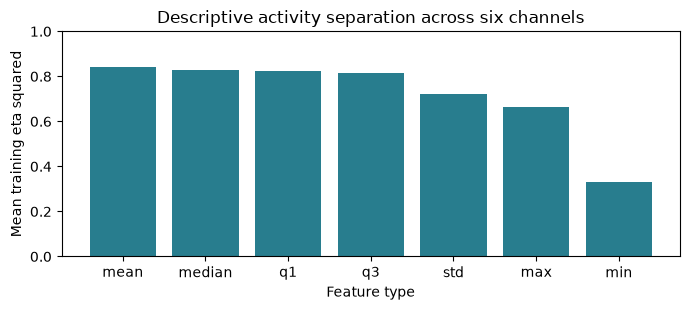

In [6]:
training = metadata.split.eq("train").to_numpy()
train_features = features.loc[training]
y = metadata.loc[training, "activity"].to_numpy()
def eta_squared(column):
    z = column.to_numpy()
    total = np.sum((z-z.mean())**2)
    between = sum(np.sum(y == g) * (z[y == g].mean()-z.mean())**2 for g in np.unique(y))
    return between/total if total > 0 else 0.0
eta = train_features.apply(eta_squared)
type_evidence = pd.DataFrame({"feature_type": TYPES,
    "mean_eta_squared": [eta[[feature_name(t,j) for j in range(1,7)]].mean() for t in TYPES]})
type_evidence = type_evidence.sort_values("mean_eta_squared", ascending=False).reset_index(drop=True)
redundancy = pd.DataFrame(index=TYPES, columns=TYPES, dtype=float)
for a, b in itertools.product(TYPES, repeat=2):
    pairs = [(train_features[feature_name(a,j)], train_features[feature_name(b,j)]) for j in range(1,7)]
    defined = [(u,v) for u,v in pairs if u.std(ddof=1) > 0 and v.std(ddof=1) > 0]
    redundancy.loc[a,b] = np.mean([abs(u.corr(v)) for u,v in defined]) if defined else np.nan
type_evidence.to_csv(RESULTS / "feature_type_evidence.csv", index=False)
redundancy.to_csv(RESULTS / "feature_type_correlations.csv")
display(type_evidence)
display(redundancy)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(type_evidence.feature_type, type_evidence.mean_eta_squared, color="#287d8e")
ax.set(xlabel="Feature type", ylabel="Mean training eta squared", ylim=(0,1), title="Descriptive activity separation across six channels")
fig.tight_layout()
fig.savefig(RESULTS / "feature_type_separation.png", dpi=180)
plt.show()
plt.close(fig)

**Selected types: mean, standard deviation, and maximum** (18 channel-specific features). Mean has the highest average training eta squared (0.8406), summarizing typical signal level. Standard deviation adds within-recording fluctuation: eta squared 0.7199 and average absolute same-channel correlation with mean only 0.6047. Maximum captures upper excursions: eta squared 0.6643, with correlations 0.7865 to mean and 0.6278 to standard deviation.

Median, q1, and q3 have strong separation (0.8273, 0.8252, and 0.8158), but correlate very strongly with mean (0.9907, 0.9796, and 0.9806). They offer less complementary information than spread and upper excursions. Minimum has the weakest average separation (0.3287) and some constant channels. Correlations involving constant columns are undefined; the correlation table averages only channels with positive variance in both types. This is a justified, interpretable choice balancing separation and redundancy, not a claim that this triplet is optimal. Bootstrap standard deviations quantify uncertainty in feature dispersion; their scale alone cannot rank predictive importance.

**Reasoning for the comparison:** eta squared divides between-group variation by total variation, making comparisons insensitive to a change of measurement units. Averaging across channels gives each channel equal weight. Correlation is an additional redundancy check: selecting three almost identical location summaries can add less information than retaining location, spread, and extremes. Neither high eta squared nor low correlation alone guarantees predictive usefulness, so this remains a descriptive judgment.

## 2. ISLR 3.7.4
The supplied textbook, printed page 128 (PDF page 137), gives n = 100 observations, one predictor, and the models
$$\mathcal L: Y=\beta_0+\beta_1X+\epsilon,\qquad
\mathcal C: Y=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon.$$
Assume ordinary unpenalized least squares on the same training observations, and independent test observations from the same population. The linear model is nested inside the cubic model by setting $\beta_2=\beta_3=0$.

### 2(a) True relationship linear: training RSS
The cubic training RSS is **no greater** than the linear training RSS. Indeed,
$$\min_{\beta_0,\beta_1,\beta_2,\beta_3}\sum_{i=1}^{100}(y_i-\beta_0-\beta_1x_i-\beta_2x_i^2-\beta_3x_i^3)^2
\leq \min_{\beta_0,\beta_1}\sum_{i=1}^{100}(y_i-\beta_0-\beta_1x_i)^2.$$
The right-hand solution is an available candidate on the left. With full column rank, independent homoskedastic errors of variance $\sigma^2>0$, and a truly linear mean, $E[RSS_L\mid X]=(100-2)\sigma^2=98\sigma^2$ and $E[RSS_C\mid X]=(100-4)\sigma^2=96\sigma^2$. These expectations follow from $RSS=\epsilon^T(I-H)\epsilon$ and $E[RSS\mid X]=\sigma^2\operatorname{tr}(I-H)=\sigma^2(n-p)$ when the true mean lies in the fitted column space and $H$ is the least-squares projection of rank $p$. Thus cubic fitting typically lowers training RSS by fitting some noise; equality is possible in special cases.

### 2(b) True relationship linear: test RSS
We expect **linear regression to have lower test RSS**, although a particular finite test set can reverse the ordering. For an independent test point,
$$E[(Y_0-\hat f(x_0))^2\mid x_0]=\sigma^2+\operatorname{Bias}[\hat f(x_0)]^2+\operatorname{Var}[\hat f(x_0)].$$
Both models contain the true linear mean and are unbiased under the usual correct-model assumptions; the extra cubic coefficients increase estimation variance without reducing bias. More precisely, let $X_L$ have columns $(1,x)$, $Z$ have columns $(x^2,x^3)$, $A=(X_L^TX_L)^{-1}X_L^TZ$, and $W=Z-X_LA$. For a test point, let $l_0=(1,x_0)^T$, $z_0=(x_0^2,x_0^3)^T$, and $w_0=z_0-A^Tl_0$. Under full rank and error covariance $\sigma^2I$,
$$\operatorname{Var}(\hat f_C(x_0)\mid X)-\operatorname{Var}(\hat f_L(x_0)\mid X)
=\sigma^2w_0^T(W^TW)^{-1}w_0\geq0.$$
The residualized cubic predictors are orthogonal to the linear predictors, giving this additive nonnegative term. Summing expected squared errors over equal-sized test sets gives the same expected RSS ordering. Equality can occur when the added predictors contribute no prediction variance at the evaluated points.

### 2(c) True relationship nonlinear: training RSS
The cubic training RSS is again **no greater** than the linear training RSS. The nested optimization inequality in 2(a) holds for every observed response vector, regardless of the true regression function. Nonlinearity is unnecessary for this training-RSS ordering; the cubic curve need not be the true function.

### 2(d) True relationship nonlinear: test RSS
There is **not enough information to order the expected test RSS**. For $m$ independent test points from the same distribution,
$$\frac{E[RSS_C-RSS_L]}{m}=E_{X_0}[\operatorname{Bias}_C^2-\operatorname{Bias}_L^2+\operatorname{Var}_C-\operatorname{Var}_L].$$
The irreducible noise cancels. A substantial quadratic or cubic component may reduce cubic-model bias enough to outweigh its larger variance; a weak departure from linearity may not. A nonlinear function can also lie outside both polynomial families, so nonlinearity alone does not establish a useful bias reduction. Without the function, noise level, and predictor distribution, either model can have lower test RSS.

**Concrete reasoning for 2(d):** a true mean $f(x)=\beta_0+\beta_1x+\delta x^2$ is nonlinear for any nonzero $\delta$. When $\delta$ is very small relative to the noise, the extra variance can dominate the small bias reduction. For a sufficiently pronounced quadratic component, that bias reduction can dominate instead. Therefore, knowing only that the relationship is nonlinear cannot determine the test-RSS ordering.


## Verification
The following checks confirm the requested data shapes, exact split, complete bootstrap results, and saved outputs. This notebook contains only Question 1 and Question 2; the extra-practice questions and Homework 4 classification tasks are excluded.

In [7]:
assert len(instances) == 88 and features.shape == (88, 42)
assert (metadata.split.eq("train").sum(), metadata.split.eq("test").sum()) == (69, 19)
assert len(bootstrap_table) == 42 and list(bootstrap_table.feature) == list(features.columns)
assert all(len(x) == n for x,n in zip(instances, audit.n_observations))
print("All checks passed: 88 instances; 42 features; 69 train / 19 test; 42 bootstrap intervals.")

All checks passed: 88 instances; 42 features; 69 train / 19 test; 42 bootstrap intervals.
